# 01 Rysunki – schemat cyklu i fazy badania

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.dates as mdates
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

from src.config import APA_STYLE, ELECTION_DAYS, FIGURES_DIR, PHASE_COLORS, PHASE_LABELS, PHASES

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(APA_STYLE)

## 2. Schemat ogólnego cyklu prezydenckiego (bez dokładnych dat)

In [2]:
END = 24.5
ELECTION = 20.15
INAUGURATION = 22.6
events = [("Ogłoszenie startu kandydatów", "wiosna roku przed wyborami", 0, 3),
          ("Prawybory i wstępne debaty", "styczeń – czerwiec", 10, 16),
          ("Konwencje nominacyjne", "lipiec – początek września", 16, 18.33),
          ("Debaty prezydenckie", "wrzesień – październik", 18, 20),
          ("Dzień wyborów", "początek listopada", ELECTION, ELECTION),
          ("Zaprzysiężenie", "20 stycznia", INAUGURATION, INAUGURATION)]
schema_phases = [("bazowa", 0, 3), ("przedwyborcza", 3, 16), ("szczytowa", 16, ELECTION),
                 ("przejsciowa", ELECTION, INAUGURATION), ("powyborcza", INAUGURATION, END)]

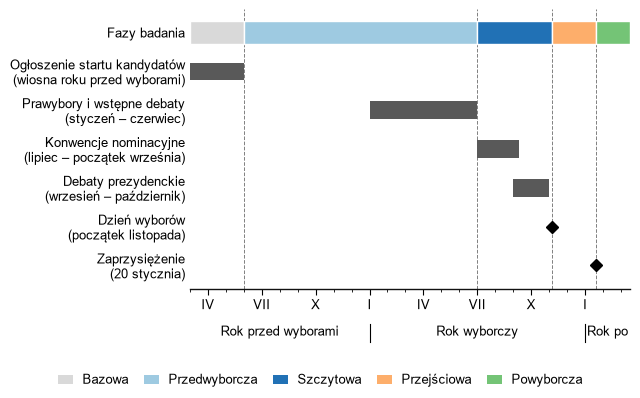

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for phase, start, end in schema_phases:
    ax.barh(0, end - start, left=start, height=0.6, color=PHASE_COLORS[phase], edgecolor="white", linewidth=1)
for row, (_, _, start, end) in enumerate(events, start=1):
    if start == end:
        ax.plot(start, row, marker="D", color="black", markersize=6)
    else:
        ax.barh(row, end - start, left=start, height=0.45, color="#595959")
for boundary in (3, 16, ELECTION, INAUGURATION):
    ax.axvline(boundary, color="0.5", lw=0.7, ls="--", zorder=0)
ax.set_ylim(len(events) + 0.6, -0.6)
ax.set_yticks(range(len(events) + 1))
ax.set_yticklabels(["Fazy badania"] + [f"{name}\n({when})" for name, when, _, _ in events])
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, END)
ax.set_xticks([1, 4, 7, 10, 13, 16, 19, 22], ["IV", "VII", "X", "I", "IV", "VII", "X", "I"])
ax.set_xticks(range(0, 25), minor=True)
for boundary in (10, 22):
    ax.axvline(boundary, ymin=-0.19, ymax=-0.125, color="black", lw=0.8, clip_on=False)
for label, center in (("Rok przed wyborami", 5), ("Rok wyborczy", 16), ("Rok po", 23.25)):
    ax.text(center, len(events) + 1.55, label, ha="center", va="top", fontsize=9)
for side in ("left", "right", "top"):
    ax.spines[side].set_visible(False)
handles = [mpatches.Patch(facecolor=PHASE_COLORS[phase], label=PHASE_LABELS[phase]) for phase, _, _ in schema_phases]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=9, columnspacing=1.2, handlelength=1.2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIGURES_DIR / "cycle_schema.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Fazy w czterech cyklach

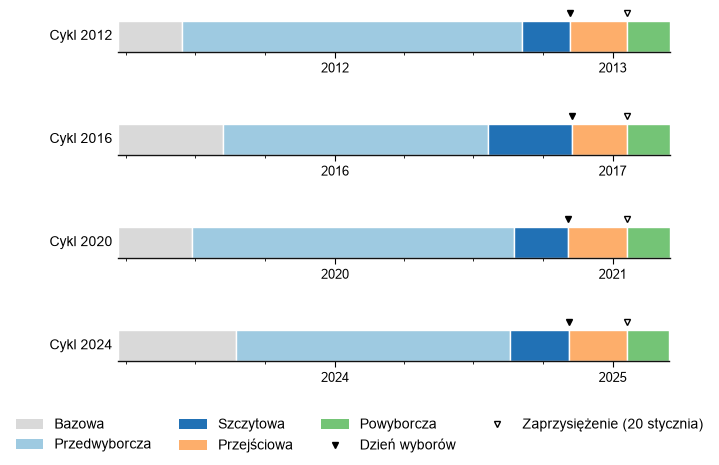

In [4]:
fig, axes = plt.subplots(len(PHASES), 1, figsize=(6.5, 4.8))
for ax, (cycle, phases) in zip(axes, PHASES.items()):
    for phase, start, end in phases:
        left = mdates.datestr2num(start)
        ax.broken_barh([(left, mdates.datestr2num(end) + 1 - left)], (0, 1), facecolors=PHASE_COLORS[phase], edgecolor="white", linewidth=1)
    ax.plot(mdates.datestr2num(ELECTION_DAYS[cycle]), 1.25, marker="v", color="black", markersize=5, clip_on=False)
    ax.plot(mdates.datestr2num(phases[-1][1]), 1.25, marker="v", markerfacecolor="white", markeredgecolor="black", markersize=5, clip_on=False)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_ylabel(f"Cykl {cycle}", rotation=0, ha="right", va="center")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=(4, 7, 10)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    for side in ("left", "right", "top"):
        ax.spines[side].set_visible(False)
    ax.set_xlim(mdates.datestr2num(phases[0][1]), mdates.datestr2num(phases[-1][2]) + 1)
handles = [mpatches.Patch(facecolor=PHASE_COLORS[phase], label=PHASE_LABELS[phase]) for phase in PHASE_LABELS]
handles += [mlines.Line2D([], [], marker="v", color="black", linestyle="", markersize=5, label="Dzień wyborów"),
            mlines.Line2D([], [], marker="v", markerfacecolor="white", markeredgecolor="black", linestyle="", markersize=5,
                          label="Zaprzysiężenie (20 stycznia)")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0.13, 1, 1), h_pad=1.8)
fig.savefig(FIGURES_DIR / "cycle_phases.png", dpi=300, bbox_inches="tight")
plt.show()